# MeteoSwiss reference meteorology: Lägern (LAE), 2004 to September 2026

***
**Site**: CH-LAE &nbsp;&nbsp;|&nbsp;&nbsp; **Reference station**: Lägern (LAE), MeteoSwiss
**Product**: 30MIN, 2004 to September 2026 (aggregated from published 10-min values)
**Author**: Lukas Hörtnagl (holukas@ethz.ch)

> **Source: MeteoSwiss.** These data are free to use; cite the source whenever they are reproduced
> or redistributed, including in figures and derived products.

## ℹ️ About this notebook
Downloads the 10-minute record of the MeteoSwiss SMN station **Lägern (`lae`)** from the open-data
STAC API, aggregates it to **30MIN** and writes one multi-variable reference product. It does not
use the InfluxDB database and applies no screening.

**Why LAE.** It is the MeteoSwiss station closest to the tower: **2.5 km** away on the same ridge,
at **845 m**, above the tower top (689 m base + 47 m). Unlike the NABEL sensors, which end in 2018,
it covers the whole record, and as a full weather station it provides references for `TA`, `RH`,
`PA` and `SW_IN` in one download.

**Parameters LAE does not measure** (checked against the data, not the station description):

| Variable | Parameter | Status |
|---|---|---|
| Precipitation | `rre150z0` | empty in every record; the precipitation reference is OED |
| Incoming longwave | `oli000z0` | empty in every record; notebook `06` (`LW_IN`) has no reference here |
| Outgoing longwave, reflected shortwave | `olo000z0`, `osr000z0` | empty |
| Soil temperature | `tso005s0`, `tso010s0`, `tso020s0` | empty |

**Coverage.** The 10-min record begins on **2004-02-01**, so January 2004 has no LAE reference.
Diffuse radiation (`ods000z0`) begins in October 2010. Completeness per year and parameter is
tabulated under *Coverage per year*.

## ⏱️ Timestamp convention
MeteoSwiss timestamps are **UTC**. In the 10-min files `reference_timestamp` marks the **end** of
the interval: a record at `t` covers `(t-10min, t]`. This matches the database's `TIMESTAMP_END`,
so the product is binned end-labelled and then shifted by `TIMEZONE_OFFSET_TO_UTC_HOURS` to local
time. The convention is verified below against the published hourly file.

**Means and spot values.** `gre000z0`, `ods000z0` and `dkl010z0` are ten-minute means, so three of
them average to a true half-hourly mean. `tre200s0`, `ure200s0`, `tde200s0`, `pva200s0` and
`prestas0` are instantaneous values, so their 30MIN value is a three-sample estimate of the
half-hourly mean. For smoothly varying quantities the difference is small but not zero.

## ✏️ Settings

In [1]:
# --- Reference station ---
STAC_COLLECTION = 'ch.meteoschweiz.ogd-smn'  # full automatic weather stations
STAC_STATION = 'lae'                         # Lägern, 47.481933 N / 8.397222 E, 845 m

# --- Time axis ---
TIMEZONE_OFFSET_TO_UTC_HOURS = 1  # UTC+01:00 (CET), as in the meteo notebooks
TARGET_FREQ = '30min'
RECORDS_PER_BIN = 3  # 10-min records in a complete 30MIN bin

# --- Period, local time (UTC+01:00) ---
START = '2004-01-01 00:00'  # start of the first period (data begin 2004-02-01)
END = '2026-10-01 00:00'    # TIMESTAMP_END of the last period, included (end of 30 Sep 2026)
YEARS = '2004-2026.09'      # period label in the file name, checked against the data before export

# --- Parameters to export: shortname -> (output column, aggregation) ---
# 'mean' for state variables and 10-min means, 'sum' for durations, 'max' for gusts,
# 'circmean' for wind direction.
PARAMS = {
    'tre200s0': ('TA_LAE_MS', 'mean'),          # air temperature 2 m [°C]
    'ure200s0': ('RH_LAE_MS', 'mean'),          # relative humidity 2 m [%]
    'tde200s0': ('TDEW_LAE_MS', 'mean'),        # dew point 2 m [°C]
    'pva200s0': ('VP_LAE_MS', 'mean'),          # vapour pressure 2 m [hPa]
    'prestas0': ('PA_LAE_MS', 'mean'),          # pressure at station altitude, QFE [hPa]
    'gre000z0': ('SW_IN_LAE_MS', 'mean'),       # global radiation [W m-2]
    'ods000z0': ('SW_IN_DIFF_LAE_MS', 'mean'),  # diffuse radiation [W m-2], from October 2010
    'sre000z0': ('SUNDUR_LAE_MS', 'sum'),       # sunshine duration [min]
    'fve010z0': ('WS_LAE_MS', 'mean'),          # wind speed, vectorial 10-min mean [m s-1]
    'fkl010z1': ('WS_GUST_LAE_MS', 'max'),      # gust peak, 1 s maximum [m s-1]
    'dkl010z0': ('WD_LAE_MS', 'circmean'),      # wind direction, 10-min mean [°]
}

# --- Output: same relative path as this notebook, under the external data folder ---
OUTDIR = (r'F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data'
          r'\workflow\10_METEO\10_REFERENCE')
OUTNAME = f'MeteoSwiss_LAE_30MIN_{YEARS}'
EXPORT_FORMATS = ('parquet', 'csv')  # parquet keeps dtypes and index; csv for inspection and sharing

### Imports

In [2]:
import io
import json
import re
import urllib.request
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option('display.max_rows', 30)
pd.set_option('display.width', 1000)
print(f"Last run: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f'pandas v{pd.__version__}')

Last run: 2026-10-23 12:20:08
pandas v3.0.3


## 🔧 Helpers

In [3]:
STAC_ITEM_URL = f'https://data.geo.admin.ch/api/stac/v1/collections/{STAC_COLLECTION}/items/{STAC_STATION}'

# Period bounds in UTC, the time base of the MeteoSwiss files.
START_UTC = pd.Timestamp(START) - pd.Timedelta(hours=TIMEZONE_OFFSET_TO_UTC_HOURS)
END_UTC = pd.Timestamp(END) - pd.Timedelta(hours=TIMEZONE_OFFSET_TO_UTC_HOURS)


def stac_assets(url: str) -> dict:
    """Return {filename: href} for a STAC item. Raises if the item has no assets."""
    with urllib.request.urlopen(url) as r:
        item = json.load(r)
    assets = {k: v['href'] for k, v in item.get('assets', {}).items()}
    if not assets:
        raise ValueError(f'STAC item {url} exposes no assets - wrong collection or station?')
    return assets


def source_files(assets: dict, res: str) -> list:
    """Files of resolution *res* ('t' 10-min, 'h' hourly) covering the period.

    Returns the `historical_<decade>` files overlapping START..END, oldest first, followed by
    the `recent` file (current year). Raises unless both kinds are found.
    """
    hist = []
    for k in sorted(assets):
        m = re.search(rf'_{res}_historical_(\d{{4}})-(\d{{4}})\.csv$', k)
        if m and int(m[1]) <= END_UTC.year and int(m[2]) >= START_UTC.year:
            hist.append(k)
    recent = [k for k in assets if k.endswith(f'_{res}_recent.csv')]
    if not hist or len(recent) != 1:
        raise ValueError(f'expected historical files and one recent file for {res!r}: {hist}, {recent}')
    return hist + recent


def read_ms_csv(href: str, params: list) -> pd.DataFrame:
    """Read one MeteoSwiss CSV and return *params* as a UTC-indexed, sorted DataFrame."""
    with urllib.request.urlopen(href) as r:
        df = pd.read_csv(io.BytesIO(r.read()), sep=';')
    missing = [p for p in params if p not in df.columns]
    if missing:
        raise ValueError(f'{missing} not in {href} (has: {list(df.columns)})')
    df['TIMESTAMP'] = pd.to_datetime(df['reference_timestamp'], format='%d.%m.%Y %H:%M')
    return df.set_index('TIMESTAMP')[params].sort_index()


def circular_mean(deg: pd.Series, freq: str) -> pd.Series:
    """Resample a direction in degrees by averaging on the unit circle.

    A linear mean fails across the 0/360 wrap (350° and 10° give 180°, not 0°),
    so the sine and cosine components are averaged instead.
    """
    rad = np.deg2rad(deg)
    res_s = np.sin(rad).resample(freq, label='right', closed='right').mean()
    res_c = np.cos(rad).resample(freq, label='right', closed='right').mean()
    return (np.rad2deg(np.arctan2(res_s, res_c)) % 360).where(res_s.notna())

### Negative control
Each helper that could silently return nothing is given bad input and must raise.

In [4]:
# Wrong collection: LAE is a full weather station, not a precip-only station.
try:
    stac_assets(f'https://data.geo.admin.ch/api/stac/v1/collections/'
                f'ch.meteoschweiz.ogd-smn-precip/items/{STAC_STATION}')
except Exception as e:
    print(f'OK, raised as expected: {type(e).__name__}')
else:
    raise AssertionError('expected a failure for the precip-only collection, got assets')

# Wrong parameter name must raise rather than return an empty frame.
try:
    read_ms_csv(stac_assets(STAC_ITEM_URL)['ogd-smn_lae_t_historical_2010-2019.csv'], ['nosuchparam'])
except ValueError as e:
    print(f'OK, raised as expected: {str(e)[:60]}...')
else:
    raise AssertionError('expected a ValueError for an unknown parameter')

# circular_mean must not return the linear mean across the 0/360 wrap.
_idx = pd.date_range('2020-01-01 00:00', periods=6, freq='10min')
_test = pd.Series([350.0, 10.0, 350.0, 10.0, 350.0, 10.0], index=_idx)
_got = circular_mean(_test, '30min').iloc[0]
assert _got > 340 or _got < 20, f'circular mean across the wrap is broken: got {_got}'
print(f'OK, circular mean of [350, 10, 350] = {_got:.1f}° (a linear mean would give 236.7°)')

OK, raised as expected: HTTPError
OK, raised as expected: ['nosuchparam'] not in https://data.geo.admin.ch/ch.meteosch...
OK, circular mean of [350, 10, 350] = 350.0° (a linear mean would give 236.7°)


## ⬇️ Available files

In [5]:
assets = stac_assets(STAC_ITEM_URL)
print(f'Station: {STAC_STATION.upper()}  |  collection: {STAC_COLLECTION}')
for k in sorted(assets):
    print(f'  {k}')

Station: LAE  |  collection: ch.meteoschweiz.ogd-smn
  ogd-smn_lae_d_historical.csv
  ogd-smn_lae_d_recent.csv
  ogd-smn_lae_h_historical_1980-1989.csv
  ogd-smn_lae_h_historical_1990-1999.csv
  ogd-smn_lae_h_historical_2000-2009.csv
  ogd-smn_lae_h_historical_2010-2019.csv
  ogd-smn_lae_h_historical_2020-2029.csv
  ogd-smn_lae_h_now.csv
  ogd-smn_lae_h_recent.csv
  ogd-smn_lae_m.csv
  ogd-smn_lae_t_historical_2000-2009.csv
  ogd-smn_lae_t_historical_2010-2019.csv
  ogd-smn_lae_t_historical_2020-2029.csv
  ogd-smn_lae_t_now.csv
  ogd-smn_lae_t_recent.csv
  ogd-smn_lae_y.csv


## 📥 Download the 10-min record
MeteoSwiss splits each record into `historical` files, which end on 31 December of the previous
year, and a `recent` file holding the current year up to the previous day. 2004-2025 come from the
10-min `historical` files and January to September 2026 from `_t_recent`; the `_now` file is not
used. Where files overlap, the `historical` value is kept. The `recent` file is updated daily, so
the 2026 values are reproducible only as long as MeteoSwiss does not revise them.

In [6]:
hires_files = source_files(assets, 't')
parts = []
for k in hires_files:
    _df = read_ms_csv(assets[k], list(PARAMS))
    print(f'  {k:<42s} {_df.index[0]} -> {_df.index[-1]} (UTC)')
    parts.append(_df)

# Historical files come first, so keep='first' gives them precedence on overlap.
raw = pd.concat(parts)
raw = raw[~raw.index.duplicated(keep='first')].sort_index()
raw = raw[(raw.index > START_UTC) & (raw.index <= END_UTC)]
assert raw.index[-1] == END_UTC, (
    f'source data end at {raw.index[-1]} UTC, before END = {END} local ({END_UTC} UTC)')
print(f'\n10MIN raw: {len(raw):,} records, {raw.index[0]} -> {raw.index[-1]} (UTC)')

raw = raw.reindex(pd.date_range(raw.index[0], END_UTC, freq='10min'))
print(f'On gapless grid: {len(raw):,} records')
print(f'\nMissing per parameter:')
for short, (name, _) in PARAMS.items():
    print(f'  {short}  {name:<20s} {raw[short].isna().mean() * 100:6.2f}%')

  ogd-smn_lae_t_historical_2000-2009.csv     2004-02-01 00:00:00 -> 2009-12-31 23:50:00 (UTC)
  ogd-smn_lae_t_historical_2010-2019.csv     2010-01-01 00:00:00 -> 2019-12-31 23:50:00 (UTC)
  ogd-smn_lae_t_historical_2020-2029.csv     2020-01-01 00:00:00 -> 2025-12-31 23:50:00 (UTC)
  ogd-smn_lae_t_recent.csv                   2026-01-01 00:00:00 -> 2026-10-22 23:50:00 (UTC)

10MIN raw: 1,191,860 records, 2004-02-01 00:00:00 -> 2026-09-30 23:00:00 (UTC)
On gapless grid: 1,192,027 records

Missing per parameter:
  tre200s0  TA_LAE_MS              0.07%
  ure200s0  RH_LAE_MS              0.08%
  tde200s0  TDEW_LAE_MS            0.08%
  pva200s0  VP_LAE_MS              0.08%
  prestas0  PA_LAE_MS              0.11%
  gre000z0  SW_IN_LAE_MS           0.03%
  ods000z0  SW_IN_DIFF_LAE_MS     29.57%
  sre000z0  SUNDUR_LAE_MS          0.04%
  fve010z0  WS_LAE_MS              0.61%
  fkl010z1  WS_GUST_LAE_MS         0.61%
  dkl010z0  WD_LAE_MS              0.10%


### Coverage per year
Percentage of 10-min records present, per calendar year (UTC). 2004 begins in February and 2026
ends in September.

In [7]:
_cov = raw.notna().groupby(raw.index.year).mean().mul(100).round(1)
_cov.columns = [PARAMS[c][0] for c in _cov.columns]
_cov

,TA_LAE_MS,RH_LAE_MS,TDEW_LAE_MS,VP_LAE_MS,PA_LAE_MS,SW_IN_LAE_MS,SW_IN_DIFF_LAE_MS,SUNDUR_LAE_MS,WS_LAE_MS,WS_GUST_LAE_MS,WD_LAE_MS
2004,100.0,100.0,100.0,100.0,100.0,100.0,0.0,100.0,100.0,100.0,100.0
2005,100.0,100.0,100.0,100.0,100.0,100.0,0.0,100.0,100.0,100.0,100.0
2006,100.0,100.0,100.0,100.0,100.0,100.0,0.0,100.0,100.0,100.0,100.0
2007,100.0,100.0,100.0,100.0,100.0,100.0,0.0,100.0,100.0,100.0,100.0
2008,100.0,100.0,100.0,100.0,100.0,100.0,0.0,100.0,100.0,100.0,100.0
2009,100.0,100.0,100.0,100.0,100.0,100.0,0.0,100.0,100.0,100.0,100.0
2010,100.0,100.0,100.0,100.0,100.0,100.0,23.6,100.0,100.0,100.0,100.0
2011,100.0,99.8,99.8,99.8,100.0,100.0,99.9,100.0,100.0,100.0,100.0
2012,99.6,99.6,99.6,99.6,99.6,99.5,99.3,99.3,99.7,99.7,99.7
2013,100.0,100.0,100.0,100.0,99.6,100.0,99.8,100.0,100.0,100.0,100.0


## ⏲️ Aggregate to 30MIN
One rule per parameter, from `PARAMS`. `N_RECORDS` counts the 10-min values in each bin, so
incomplete bins can be identified downstream.

In [8]:
def aggregate(df: pd.DataFrame, freq: str) -> pd.DataFrame:
    """Aggregate 10-min (end-labelled) values to *freq*, one rule per parameter."""
    res = df.resample(freq, label='right', closed='right')
    out = {}
    for short, (name, how) in PARAMS.items():
        if how == 'mean':
            out[name] = res[short].mean()
        elif how == 'sum':
            out[name] = res[short].sum(min_count=1)  # min_count: all-NaN stays NaN, not 0
        elif how == 'max':
            out[name] = res[short].max()
        elif how == 'circmean':
            out[name] = circular_mean(df[short], freq)
        else:
            raise ValueError(f'unknown aggregation {how!r} for {short}')
    out['N_RECORDS'] = res['tre200s0'].count()
    return pd.DataFrame(out)


lae30 = aggregate(raw, TARGET_FREQ)
print(f'{TARGET_FREQ}: {len(lae30):,} periods, {lae30.index[0]} -> {lae30.index[-1]} (UTC)')
_inc = lae30['N_RECORDS'] < RECORDS_PER_BIN
print(f'Incomplete bins (N_RECORDS < {RECORDS_PER_BIN}): {_inc.sum():,} ({_inc.mean() * 100:.3f}%)')
lae30.head()

30min: 397,343 periods, 2004-02-01 00:00:00 -> 2026-09-30 23:00:00 (UTC)
Incomplete bins (N_RECORDS < 3): 279 (0.070%)


,TA_LAE_MS,RH_LAE_MS,TDEW_LAE_MS,VP_LAE_MS,PA_LAE_MS,SW_IN_LAE_MS,SW_IN_DIFF_LAE_MS,SUNDUR_LAE_MS,WS_LAE_MS,WS_GUST_LAE_MS,WD_LAE_MS,N_RECORDS
2004-02-01 00:00:00,4.400000,81.200000,1.500000,6.800000,921.100000,0.0,NaN,0.0,10.400000,21.0,219.000000,1
2004-02-01 00:30:00,4.466667,80.700000,1.433333,6.800000,921.166667,2.0,NaN,0.0,11.500000,25.0,216.999898,3
2004-02-01 01:00:00,4.533333,80.633333,1.466667,6.800000,921.066667,2.0,NaN,0.0,12.233333,26.5,216.333296,3
2004-02-01 01:30:00,4.700000,80.333333,1.600000,6.900000,921.500000,2.0,NaN,0.0,11.100000,23.1,217.000000,3
2004-02-01 02:00:00,4.600000,80.733333,1.566667,6.833333,921.633333,2.0,NaN,0.0,11.966667,24.8,217.000000,3


### Guard: binning
Shows the three 10-min records behind one half-hour, so the `(t-30min, t]` convention is
demonstrated on data rather than asserted.

In [9]:
_probe = pd.Timestamp('2015-06-15 10:00')
_window = raw.loc[_probe - pd.Timedelta(minutes=20):_probe, ['tre200s0', 'gre000z0']]
print(f'10-min records feeding the bin labelled {_probe}:')
print(_window.to_string())
print(f'\nmean TA  = {_window["tre200s0"].mean():.4f}  '
      f'-> exported {lae30.loc[_probe, "TA_LAE_MS"]:.4f}')
print(f'mean SW  = {_window["gre000z0"].mean():.4f}  '
      f'-> exported {lae30.loc[_probe, "SW_IN_LAE_MS"]:.4f}')

assert np.isclose(_window['tre200s0'].mean(), lae30.loc[_probe, 'TA_LAE_MS'])
assert np.isclose(_window['gre000z0'].mean(), lae30.loc[_probe, 'SW_IN_LAE_MS'])
assert lae30.loc[_probe, 'N_RECORDS'] == RECORDS_PER_BIN
print('\nOK: the bin labelled t is the mean over (t-30min, t]')

10-min records feeding the bin labelled 2015-06-15 10:00:00:
                     tre200s0  gre000z0
2015-06-15 09:40:00      12.2     224.0
2015-06-15 09:50:00      12.2     250.0
2015-06-15 10:00:00      12.5     237.0

mean TA  = 12.3000  -> exported 12.3000
mean SW  = 237.0000  -> exported 237.0000

OK: the bin labelled t is the mean over (t-30min, t]


### Sanity checks

In [10]:
# Axis is continuous, unique and at the expected resolution.
assert lae30.index.is_monotonic_increasing, 'index not sorted'
assert not lae30.index.has_duplicates, 'duplicate timestamps'
_diffs = lae30.index.to_series().diff().dropna().unique()
assert len(_diffs) == 1 and _diffs[0] == pd.Timedelta(TARGET_FREQ), f'irregular index: {_diffs}'

# Physical ranges, deliberately generous: a guard against unit or sign errors, not a screening.
RANGES = {'TA_LAE_MS': (-30, 45), 'RH_LAE_MS': (0, 100), 'TDEW_LAE_MS': (-40, 30),
          'VP_LAE_MS': (0, 50), 'PA_LAE_MS': (850, 950), 'SW_IN_LAE_MS': (-20, 1400),
          'SW_IN_DIFF_LAE_MS': (-20, 1000), 'SUNDUR_LAE_MS': (0, 30),
          'WS_LAE_MS': (0, 60), 'WS_GUST_LAE_MS': (0, 80), 'WD_LAE_MS': (0, 360)}
for col, (lo, hi) in RANGES.items():
    s = lae30[col].dropna()
    assert s.between(lo, hi).all(), (
        f'{col} outside [{lo}, {hi}]: min {s.min()}, max {s.max()}')
    print(f'  {col:<20s} {s.min():>9.2f} .. {s.max():>9.2f}   OK')
print('\nAll sanity checks passed.')

  TA_LAE_MS               -17.70 ..     33.37   OK
  RH_LAE_MS                 3.67 ..    100.00   OK
  TDEW_LAE_MS             -27.03 ..     21.43   OK
  VP_LAE_MS                 0.67 ..     25.57   OK
  PA_LAE_MS               881.70 ..    942.53   OK
  SW_IN_LAE_MS              0.00 ..   1155.33   OK
  SW_IN_DIFF_LAE_MS         0.00 ..    640.33   OK
  SUNDUR_LAE_MS             0.00 ..     30.00   OK
  WS_LAE_MS                 0.00 ..     17.40   OK
  WS_GUST_LAE_MS            0.00 ..     37.60   OK
  WD_LAE_MS                 0.00 ..    360.00   OK

All sanity checks passed.


## ✅ Cross-check against the published hourly file
Rolling the 30MIN product up to hourly and comparing it with the published **hourly** product is an
independent check of the timestamp convention. The two agree in the mean but not record by record,
as expected: MeteoSwiss computes the hourly file from unpublished high-frequency samples, not from
the 10-min file. This is therefore a bias check, not an equality check; a mean difference near zero
confirms the alignment.

In [11]:
HOURLY = {'tre200h0': 'TA_LAE_MS', 'ure200h0': 'RH_LAE_MS',
          'gre000h0': 'SW_IN_LAE_MS', 'prestah0': 'PA_LAE_MS'}
_hfiles = source_files(assets, 'h')
pub_h = pd.concat([read_ms_csv(assets[k], list(HOURLY)) for k in _hfiles])
pub_h = pub_h[~pub_h.index.duplicated(keep='first')].sort_index()
pub_h = pub_h[(pub_h.index > START_UTC) & (pub_h.index <= END_UTC)]

mine_h = lae30[list(HOURLY.values())].resample('h', label='right', closed='right').mean()

print(f'{"parameter":<14s} {"n":>8s} {"mean diff":>12s} {"median |d|":>12s} {"corr":>10s}')
for short, name in HOURLY.items():
    j = pd.concat([mine_h[name].rename('mine'), pub_h[short].rename('pub')], axis=1).dropna()
    d = j['mine'] - j['pub']
    print(f'{name:<14s} {len(j):>8,} {d.mean():>+12.4f} {d.abs().median():>12.4f} '
          f'{j["mine"].corr(j["pub"]):>10.6f}')

parameter             n    mean diff   median |d|       corr
TA_LAE_MS       198,534      -0.0056       0.0667   0.998984
RH_LAE_MS       198,515      -0.0067       0.1333   0.991596
SW_IN_LAE_MS    198,610      -0.0721       0.3333   0.978564
PA_LAE_MS       198,452      -0.0050       0.0500   0.999648


C:\Users\holukas\AppData\Local\Temp\ipykernel_19076\3265542169.py:12: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  j = pd.concat([mine_h[name].rename('mine'), pub_h[short].rename('pub')], axis=1).dropna()
C:\Users\holukas\AppData\Local\Temp\ipykernel_19076\3265542169.py:12: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  j = pd.concat([mine_h[name].rename('mine'), pub_h[short].rename('pub')], axis=1).dropna()
C:\Users\holukas\AppData\Local\Temp\ipykernel_19076\3265542169.py:12: Pandas4Warning

### Guard: the alignment is not accidental
Shifting the aggregation away from the end-labelled convention must make the agreement worse. If
another offset fitted better, the convention would be wrong, and an offset reference would corrupt
every comparison built on it, including the radiation-based timestamp-shift check.

In [12]:
_ref = pub_h['gre000h0']
_scores = {}
for _off in range(0, 4):
    _shifted = lae30['SW_IN_LAE_MS'].shift(_off)
    _h = _shifted.resample('h', label='right', closed='right').mean()
    _j = pd.concat([_h.rename('m'), _ref.rename('p')], axis=1).dropna()
    _scores[_off] = ((_j['m'] - _j['p']) ** 2).mean() ** 0.5
    print(f'  offset {_off} x 30min: rmse {_scores[_off]:8.4f}')

assert min(_scores, key=_scores.get) == 0, (
    f'a non-zero offset fits better ({_scores}) - the timestamp convention is wrong')
print('\nOK: offset 0 wins, and agreement degrades monotonically away from it.')

C:\Users\holukas\AppData\Local\Temp\ipykernel_19076\382275319.py:6: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  _j = pd.concat([_h.rename('m'), _ref.rename('p')], axis=1).dropna()


  offset 0 x 30min: rmse  47.8160
  offset 1 x 30min: rmse  80.7543
  offset 2 x 30min: rmse 111.4872
  offset 3 x 30min: rmse 139.6894

OK: offset 0 wins, and agreement degrades monotonically away from it.


C:\Users\holukas\AppData\Local\Temp\ipykernel_19076\382275319.py:6: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  _j = pd.concat([_h.rename('m'), _ref.rename('p')], axis=1).dropna()
C:\Users\holukas\AppData\Local\Temp\ipykernel_19076\382275319.py:6: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  _j = pd.concat([_h.rename('m'), _ref.rename('p')], axis=1).dropna()
C:\Users\holukas\AppData\Local\Temp\ipykernel_19076\382275319.py:6: Pandas4Warning: Sorting by default when concatenating all Dateti

## 🌍 Shift to local time
After the shift the product carries `TIMESTAMP_END` in local time, as the meteo products do. The
period label `YEARS` is then checked against the data.

In [13]:
lae_out = lae30.copy()
lae_out.index = lae_out.index + pd.Timedelta(hours=TIMEZONE_OFFSET_TO_UTC_HOURS)
lae_out.index.name = 'TIMESTAMP_END'
lae_out['FLAG_INCOMPLETE'] = (lae_out['N_RECORDS'] < RECORDS_PER_BIN).astype(int)

assert lae_out.index[-1] == pd.Timestamp(END), (
    f'last record ends {lae_out.index[-1]}, expected END = {END}')

# The label comes from the bins' starts, not their labels: end-labelling puts the last bin
# of a month at 00:00 on the following day, and the local shift moves every stamp again.
_first_start = lae_out.index[0] - pd.Timedelta(TARGET_FREQ)
_last_start = lae_out.index[-1] - pd.Timedelta(TARGET_FREQ)
_full_year = pd.Timestamp(END) == pd.Timestamp(year=pd.Timestamp(END).year, month=1, day=1)
_derived = f'{_first_start:%Y}-' + (f'{_last_start:%Y}' if _full_year else f'{_last_start:%Y.%m}')
assert YEARS == _derived, f'YEARS = {YEARS!r}, but the data give {_derived!r}'
print(f'First bin starts {_first_start}, last bin starts {_last_start} -> {YEARS}')
print(f'Local (UTC+{TIMEZONE_OFFSET_TO_UTC_HOURS}): {lae_out.index[0]} -> {lae_out.index[-1]}')
lae_out.head()

First bin starts 2004-02-01 00:30:00, last bin starts 2026-09-30 23:30:00 -> 2004-2026.09
Local (UTC+1): 2004-02-01 01:00:00 -> 2026-10-01 00:00:00


,TA_LAE_MS,RH_LAE_MS,TDEW_LAE_MS,VP_LAE_MS,PA_LAE_MS,SW_IN_LAE_MS,SW_IN_DIFF_LAE_MS,SUNDUR_LAE_MS,WS_LAE_MS,WS_GUST_LAE_MS,WD_LAE_MS,N_RECORDS,FLAG_INCOMPLETE
TIMESTAMP_END,,,,,,,,,,,,,
2004-02-01 01:00:00,4.400000,81.200000,1.500000,6.800000,921.100000,0.0,NaN,0.0,10.400000,21.0,219.000000,1,1
2004-02-01 01:30:00,4.466667,80.700000,1.433333,6.800000,921.166667,2.0,NaN,0.0,11.500000,25.0,216.999898,3,0
2004-02-01 02:00:00,4.533333,80.633333,1.466667,6.800000,921.066667,2.0,NaN,0.0,12.233333,26.5,216.333296,3,0
2004-02-01 02:30:00,4.700000,80.333333,1.600000,6.900000,921.500000,2.0,NaN,0.0,11.100000,23.1,217.000000,3,0
2004-02-01 03:00:00,4.600000,80.733333,1.566667,6.833333,921.633333,2.0,NaN,0.0,11.966667,24.8,217.000000,3,0


## 📊 Plots

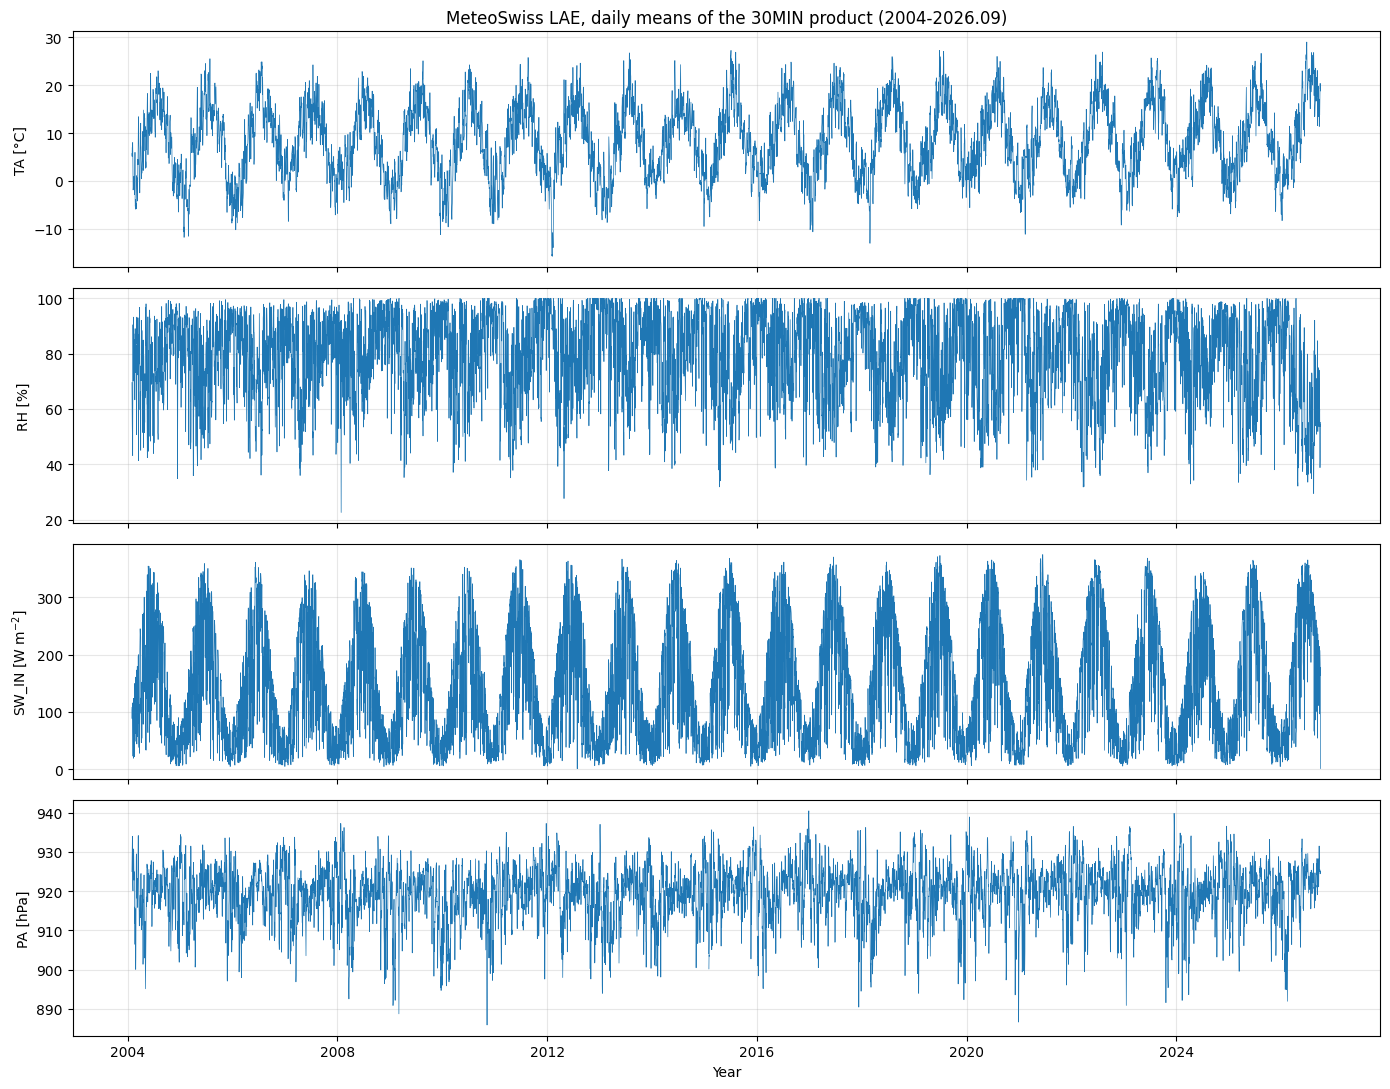

In [14]:
fig, axes = plt.subplots(4, 1, figsize=(14, 11), sharex=True)
for ax, col, lab in [(axes[0], 'TA_LAE_MS', 'TA [°C]'),
                     (axes[1], 'RH_LAE_MS', 'RH [%]'),
                     (axes[2], 'SW_IN_LAE_MS', r'SW_IN [W m$^{-2}$]'),
                     (axes[3], 'PA_LAE_MS', 'PA [hPa]')]:
    _d = lae_out[col].resample('D').mean()
    ax.plot(_d.index, _d, lw=.5, color='tab:blue')
    ax.set_ylabel(lab)
    ax.grid(alpha=.3)
axes[0].set_title(f'MeteoSwiss LAE, daily means of the 30MIN product ({YEARS})')
axes[-1].set_xlabel('Year')
fig.tight_layout()
plt.show()

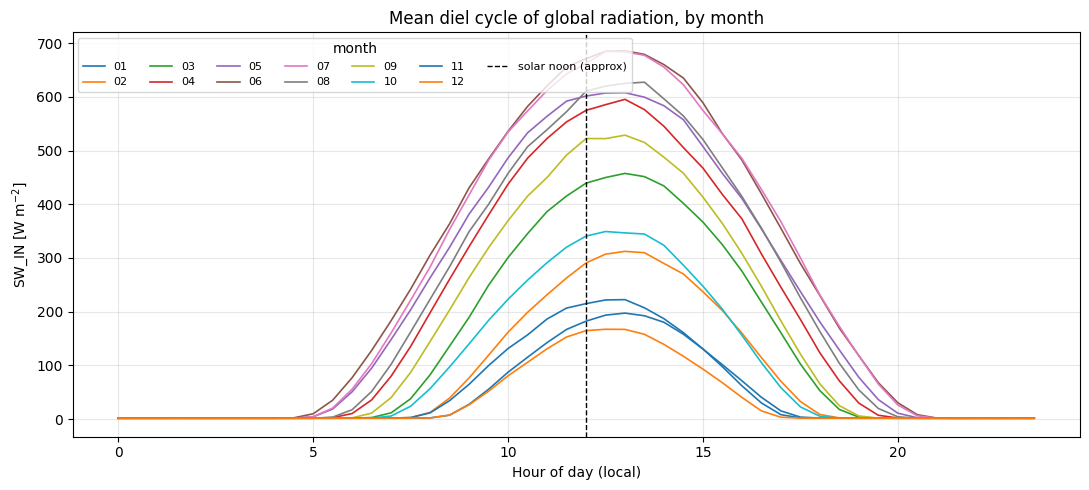

In [15]:
# Mean diel cycle per month: a shape check. A timestamp error would show as a
# radiation curve that is not centred on solar noon.
_sw = lae_out['SW_IN_LAE_MS']
_dc = _sw.groupby([_sw.index.month, _sw.index.hour + _sw.index.minute / 60]).mean().unstack(0)
fig, ax = plt.subplots(figsize=(11, 5))
for _m in _dc.columns:
    ax.plot(_dc.index, _dc[_m], label=f'{_m:02d}', lw=1.2)
ax.axvline(12 + TIMEZONE_OFFSET_TO_UTC_HOURS - 1, color='k', ls='--', lw=1,
           label='solar noon (approx)')
ax.set_xlabel('Hour of day (local)')
ax.set_ylabel(r'SW_IN [W m$^{-2}$]')
ax.set_title('Mean diel cycle of global radiation, by month')
ax.legend(ncol=7, fontsize=8, title='month')
ax.grid(alpha=.3)
fig.tight_layout()
plt.show()

## 💾 Export

In [16]:
outdir = Path(OUTDIR)
outdir.mkdir(parents=True, exist_ok=True)

written = {}
for fmt in EXPORT_FORMATS:
    path = outdir / f'{OUTNAME}.{fmt}'
    if fmt == 'parquet':
        lae_out.to_parquet(path)
    elif fmt == 'csv':
        # NaN is written as an empty field, so a gap cannot be read back as a value.
        lae_out.to_csv(path, index=True, na_rep='')
    else:
        raise ValueError(f'unsupported export format: {fmt}')
    written[fmt] = path
    print(f'Wrote {path.name:<45s} ({path.stat().st_size / 1024:>8.0f} KB)')
print(f'\n  in {outdir}')

Wrote MeteoSwiss_LAE_30MIN_2004-2026.09.parquet     (    8992 KB)
Wrote MeteoSwiss_LAE_30MIN_2004-2026.09.csv         (   62911 KB)

  in F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\10_REFERENCE


### Read the written file back
Checks the file on disk against the exported frame.

In [17]:
back = pd.read_parquet(written['parquet'])
print(f'{len(back):,} records, {back.index[0]} -> {back.index[-1]}')
print(f'columns: {list(back.columns)}')
assert back.index.name == 'TIMESTAMP_END'
assert len(back) == len(lae_out)
assert back.index[-1] == pd.Timestamp(END)
assert back['TA_LAE_MS'].notna().sum() == lae_out['TA_LAE_MS'].notna().sum()
print('\nOK: file on disk matches the exported frame.')
back.describe().round(2)

397,343 records, 2004-02-01 01:00:00 -> 2026-10-01 00:00:00
columns: ['TA_LAE_MS', 'RH_LAE_MS', 'TDEW_LAE_MS', 'VP_LAE_MS', 'PA_LAE_MS', 'SW_IN_LAE_MS', 'SW_IN_DIFF_LAE_MS', 'SUNDUR_LAE_MS', 'WS_LAE_MS', 'WS_GUST_LAE_MS', 'WD_LAE_MS', 'N_RECORDS', 'FLAG_INCOMPLETE']

OK: file on disk matches the exported frame.


,TA_LAE_MS,RH_LAE_MS,TDEW_LAE_MS,VP_LAE_MS,PA_LAE_MS,SW_IN_LAE_MS,SW_IN_DIFF_LAE_MS,SUNDUR_LAE_MS,WS_LAE_MS,WS_GUST_LAE_MS,WD_LAE_MS,N_RECORDS,FLAG_INCOMPLETE
count,397072.00,397036.00,397036.00,397036.00,396912.00,397230.00,279941.00,397198.00,394929.00,394929.00,396945.00,397343.00,397343.00
mean,8.45,78.88,4.42,9.12,919.51,143.27,59.64,6.31,4.44,7.38,173.21,3.00,0.00
std,7.95,18.92,6.43,3.90,7.36,233.20,92.26,11.43,2.36,3.91,100.22,0.08,0.03
min,-17.70,3.67,-27.03,0.67,881.70,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,2.33,65.03,-0.47,5.90,915.67,2.00,0.67,0.00,2.67,4.50,55.67,3.00,0.00
50%,8.43,82.77,4.60,8.47,920.47,5.67,4.67,0.00,4.17,6.70,203.14,3.00,0.00
75%,14.37,96.63,9.63,11.97,924.30,193.00,87.33,5.00,5.90,9.40,236.33,3.00,0.00
max,33.37,100.00,21.43,25.57,942.53,1155.33,640.33,30.00,17.40,37.60,360.00,3.00,1.00


***
### Note for downstream users
This product is a **reference**, not a screened series: the published MeteoSwiss values aggregated
to 30MIN, with no outlier removal, gap-filling or corrections. Gaps are retained. `FLAG_INCOMPLETE`
marks bins built from fewer than three 10-min records.

- **`PA_LAE_MS` is measured at 845 m**, the tower barometer at about 689 m. The hydrostatic offset
  of about 156 m of air (order 15 hPa) must be accounted for before comparing the two.
- **January 2004 is absent**, and diffuse radiation begins in October 2010.
- **January to September 2026 come from the `recent` file** and may differ from the later
  `historical` release if MeteoSwiss revises them.

In [18]:
print(f"Finished: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

Finished: 2026-10-23 12:20:26
